<a href="https://colab.research.google.com/github/nurfnick/Numerical_Methods/blob/master/Module_1_Errors/FloatingPtProblems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Examining Floating-Point Approximation and Catastrophic Cancellation
We want to analyze the function $f(x) = \frac{e^x - 1}{x} - 1$ very close to $x = 0$. Mathematically, $\lim_{x \to 0} f(x) = 0$. However, using standard 64-bit floating-point representation (`double`), when $x$ is extremely close to $0$, $e^x$ is extremely close to $1$. Subtracting $1$ from it leads to catastrophic cancellation (loss of precision).

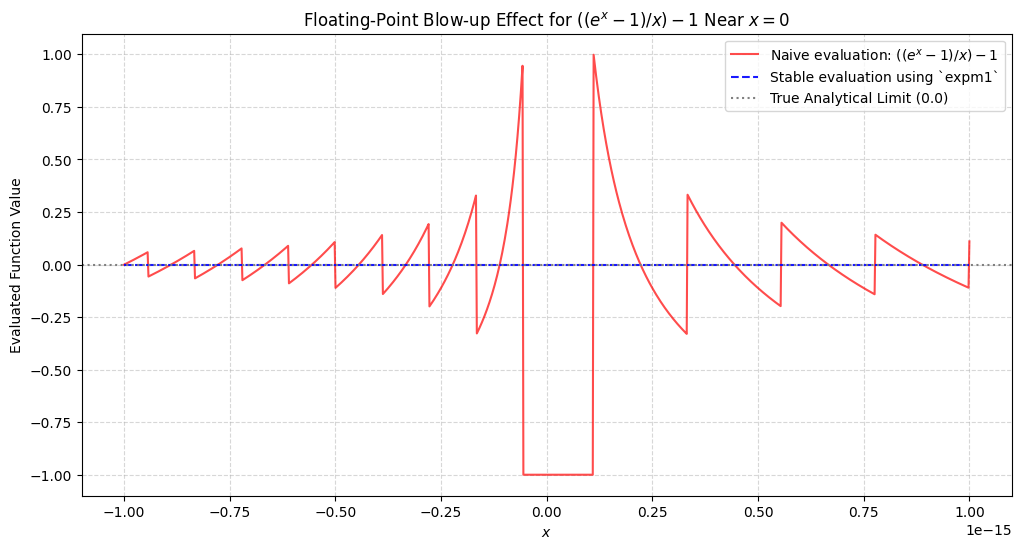

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# We will vary x in an extremely small window around 0
x = np.linspace(-1e-15, 1e-15, 1000)

# Direct (naive) evaluation
y_naive = ((np.exp(x) - 1) / x) - 1

# Numerically stable evaluation using np.expm1(x) which computes exp(x) - 1 accurately
y_stable = (np.expm1(x) / x) - 1

# Set up the plot
plt.figure(figsize=(12, 6))
plt.plot(x, y_naive, label='Naive evaluation: $((e^x - 1)/x) - 1$', color='red', alpha=0.7)
plt.plot(x, y_stable, label='Stable evaluation using `expm1`', color='blue', linestyle='--', alpha=0.9)
plt.axhline(0.0, color='gray', linestyle=':', label='True Analytical Limit (0.0)')

plt.title('Floating-Point Blow-up Effect for $((e^x - 1)/x) - 1$ Near $x=0$')
plt.xlabel('$x$')
plt.ylabel('Evaluated Function Value')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()